# Estudio de la base de datos BDIADelivery final (MySQL)

**Proyecto 1 · IA DELIVERY SL** — Marc Fernández, Pol Carvajal, Javier Givica

Repetimos el estudio previo con la base de datos final que nos dieron los profesores (`data/raw/BDIADelivery_MySQL.sql`).
La inicial tenía las coordenadas de los destinos generadas al azar; ya no está en el repositorio, pero su análisis
se conserva en `notebooks/obsoleta/01_analisis_bbdd_inicial.ipynb` (figuras en `docs/img/eda/`).
Las figuras de este notebook se guardan en `docs/img/eda_final/`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from ia_delivery.data import load_tables, build_orders, MATARO_LAT, MATARO_LON

IMG = ROOT / "docs" / "img" / "eda_final"
IMG.mkdir(parents=True, exist_ok=True)

# Estilo común de las figuras
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 200, "figure.facecolor": FONDO, "axes.facecolor": FONDO,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "text.color": TINTA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": .8, "axes.axisbelow": True,
})
miles = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

def guardar(fig, nombre):
    fig.savefig(IMG / f"{nombre}.png", bbox_inches="tight", facecolor=FONDO)
    plt.show()

t = load_tables(ROOT / "data" / "processed")
P = t["Productos"].copy()
P["Tipo"] = P["Nombre"].str.rsplit(" ", n=1).str[0]
L = t["LineasPedido"].merge(P, on="IdProducto")
O = build_orders(t)
print({k: v.shape for k, v in t.items()})

{'Clientes': (500, 5), 'Destinos': (1500, 10), 'LineasPedido': (17689, 4), 'Pedidos': (133, 4), 'Productos': (10000, 5), 'Provincias': (47, 2)}


## 1. Volumen y calidad básica de cada tabla

In [2]:
pd.DataFrame({
    "filas": {k: len(v) for k, v in t.items()},
    "columnas": {k: v.shape[1] for k, v in t.items()},
    "nulos": {k: int(v.isna().sum().sum()) for k, v in t.items()},
    "duplicados": {k: int(v.duplicated().sum()) for k, v in t.items()},
})

,filas,columnas,nulos,duplicados
Clientes,500,5,0,0
Destinos,1500,10,0,0
LineasPedido,17689,4,0,0
Pedidos,133,4,0,0
Productos,10000,5,0,0
Provincias,47,2,0,0


## 2. Productos

Hay 10 tipos de producto con 1.000 variantes cada uno. Lo importante para el reparto es la **caducidad**, que depende solo del tipo.

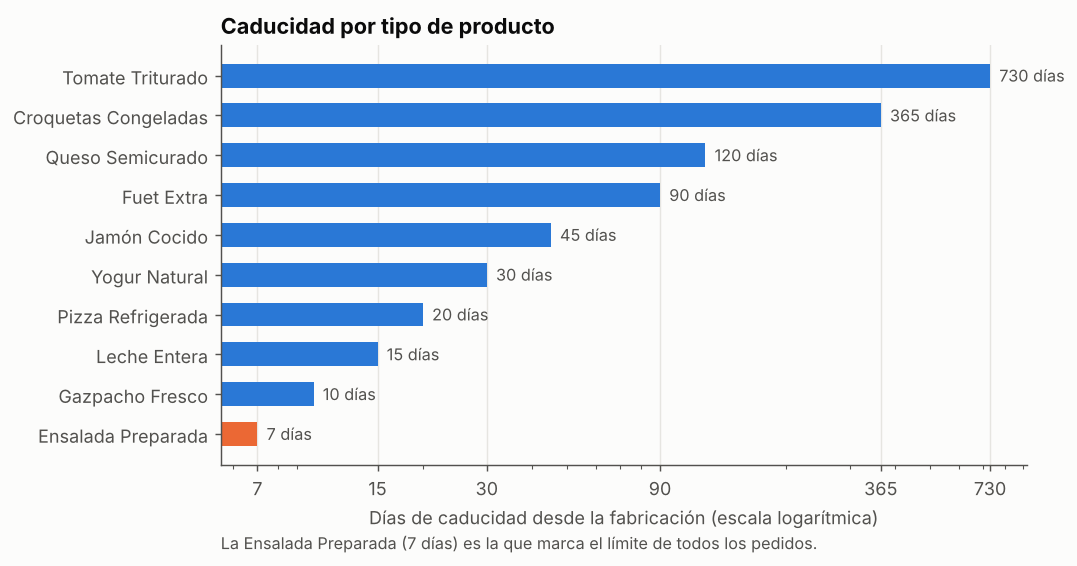

In [3]:
cad = P.groupby("Tipo")["CaducidadDias"].first().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
colores = [NARANJA if v == cad.min() else AZUL for v in cad.values]
ax.barh(cad.index, cad.values, color=colores, height=.6)
ax.set_xscale("log"); ax.set_xticks([7, 15, 30, 90, 365, 730]); ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}"))
ax.grid(axis="y", visible=False)
for y, v in enumerate(cad.values):
    ax.text(v * 1.06, y, f"{v} días", va="center", fontsize=9, color=TINTA2)
ax.set_xlabel("Días de caducidad desde la fabricación (escala logarítmica)")
ax.set_title("Caducidad por tipo de producto")
ax.text(0, -0.2, "La Ensalada Preparada (7 días) es la que marca el límite de todos los pedidos.",
        transform=ax.transAxes, fontsize=9, color=TINTA2)
guardar(fig, "eda_01_caducidad_por_tipo")

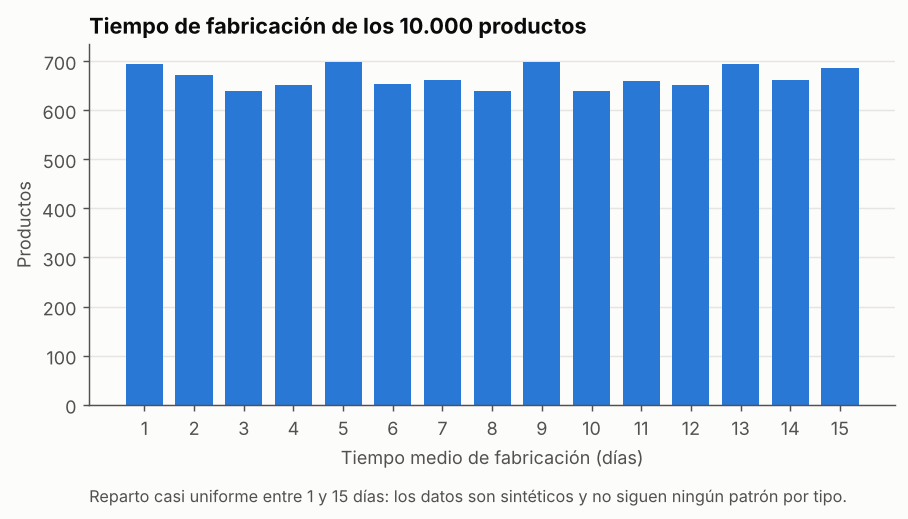

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
fab = P["TiempoFabricacionMedioDias"].value_counts().sort_index()
ax.bar(fab.index, fab.values, color=AZUL, width=.75)
ax.set_xticks(range(1, 16)); ax.grid(axis="x", visible=False)
ax.set_xlabel("Tiempo medio de fabricación (días)"); ax.set_ylabel("Productos")
ax.set_title("Tiempo de fabricación de los 10.000 productos")
ax.text(0, -0.27, "Reparto casi uniforme entre 1 y 15 días: los datos son sintéticos y no siguen ningún patrón por tipo.",
        transform=ax.transAxes, fontsize=9, color=TINTA2)
guardar(fig, "eda_02_fabricacion")

## 3. Pedidos: qué contienen y cuánto ocupan

Pedidos que contienen cada tipo (%): {'Croquetas Congeladas': 100.0, 'Ensalada Preparada': 100.0, 'Fuet Extra': 100.0, 'Gazpacho Fresco': 100.0, 'Jamón Cocido': 100.0, 'Leche Entera': 100.0, 'Pizza Refrigerada': 100.0, 'Queso Semicurado': 100.0, 'Tomate Triturado': 100.0, 'Yogur Natural': 100.0}
Líneas por pedido: min 133 max 133
Fechas de pedido distintas: 1


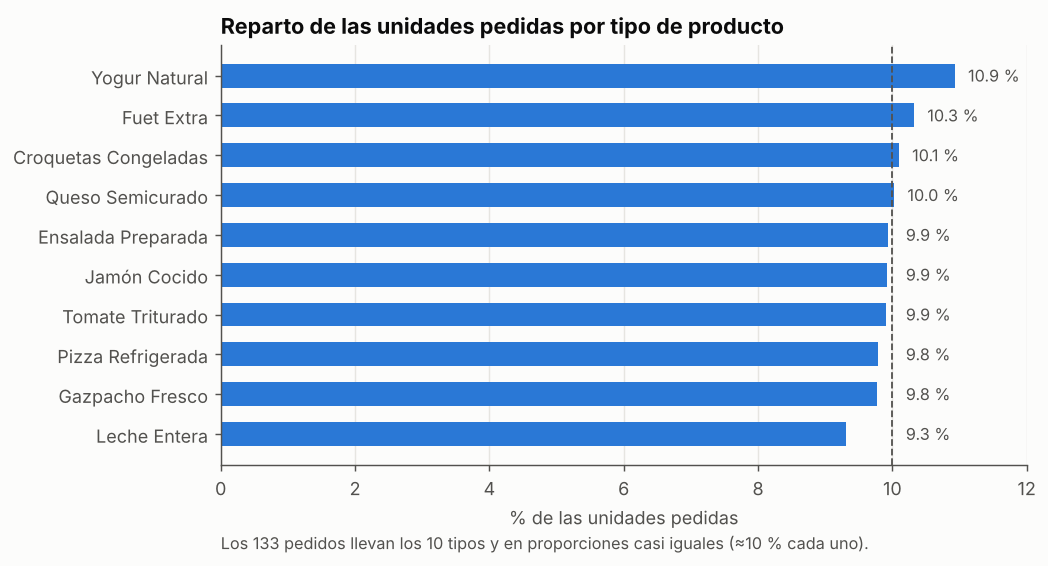

In [5]:
presencia = L.groupby("Tipo")["IdPedido"].nunique() / len(O) * 100
reparto = L.groupby("Tipo")["Cantidad"].sum() / L["Cantidad"].sum() * 100
print("Pedidos que contienen cada tipo (%):", presencia.round(1).to_dict())
print("Líneas por pedido: min", O.NumLineas.min(), "max", O.NumLineas.max())
print("Fechas de pedido distintas:", O.FechaPedido.nunique())

fig, ax = plt.subplots(figsize=(8, 4.2))
r = reparto.sort_values()
ax.barh(r.index, r.values, color=AZUL, height=.6)
ax.axvline(10, color=TINTA2, lw=1, ls="--")
ax.grid(axis="y", visible=False)
for y, v in enumerate(r.values):
    ax.text(max(v, 10) + .2, y, f"{v:.1f} %", va="center", fontsize=9, color=TINTA2)
ax.set_xlim(0, 12); ax.set_xlabel("% de las unidades pedidas")
ax.set_title("Reparto de las unidades pedidas por tipo de producto")
ax.text(0, -0.2, "Los 133 pedidos llevan los 10 tipos y en proporciones casi iguales (≈10 % cada uno).",
        transform=ax.transAxes, fontsize=9, color=TINTA2)
guardar(fig, "eda_03_composicion_pedidos")

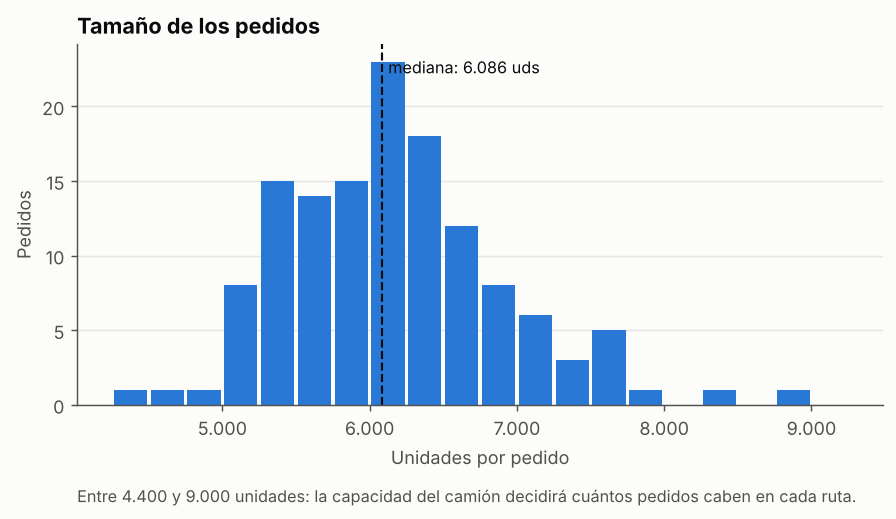

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(O["Unidades"], bins=np.arange(4250, 9251, 250), color=AZUL, rwidth=.9)
med = O["Unidades"].median()
ax.axvline(med, color=TINTA, lw=1.2, ls="--")
ax.text(med + 40, ax.get_ylim()[1] * .92, f"mediana: {med:,.0f} uds".replace(",", "."), fontsize=9)
ax.xaxis.set_major_formatter(miles); ax.yaxis.get_major_locator().set_params(integer=True); ax.grid(axis="x", visible=False)
ax.set_xlabel("Unidades por pedido"); ax.set_ylabel("Pedidos")
ax.set_title("Tamaño de los pedidos")
ax.text(0, -0.27, "Entre 4.400 y 9.000 unidades: la capacidad del camión decidirá cuántos pedidos caben en cada ruta.",
        transform=ax.transAxes, fontsize=9, color=TINTA2)
guardar(fig, "eda_04_unidades_pedido")

## 4. Distancias desde Mataró

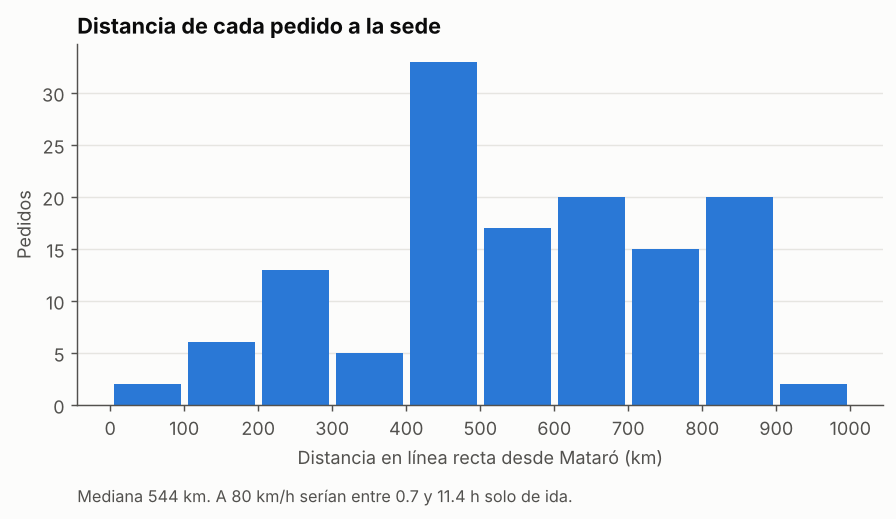

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(O["DistanciaKm"], bins=np.arange(0, 1001, 100), color=AZUL, rwidth=.9)
ax.set_xticks(range(0, 1001, 100)); ax.grid(axis="x", visible=False)
ax.set_xlabel("Distancia en línea recta desde Mataró (km)"); ax.set_ylabel("Pedidos")
ax.set_title("Distancia de cada pedido a la sede")
h = O["DistanciaKm"] / 80
ax.text(0, -0.27, f"Mediana {O['DistanciaKm'].median():.0f} km. A 80 km/h serían entre {h.min():.1f} y {h.max():.1f} h solo de ida.",
        transform=ax.transAxes, fontsize=9, color=TINTA2)
guardar(fig, "eda_05_distancias")

## 5. Caducidad de los pedidos

Fórmula del enunciado por producto: `FechaPedido + 1 día + TiempoFabricación + DíasCaducidad`; la del pedido es la mínima. El camión no puede salir hasta que se fabrica el producto más lento, así que el margen de reparto es `FechaCaducidad − FechaListo`.

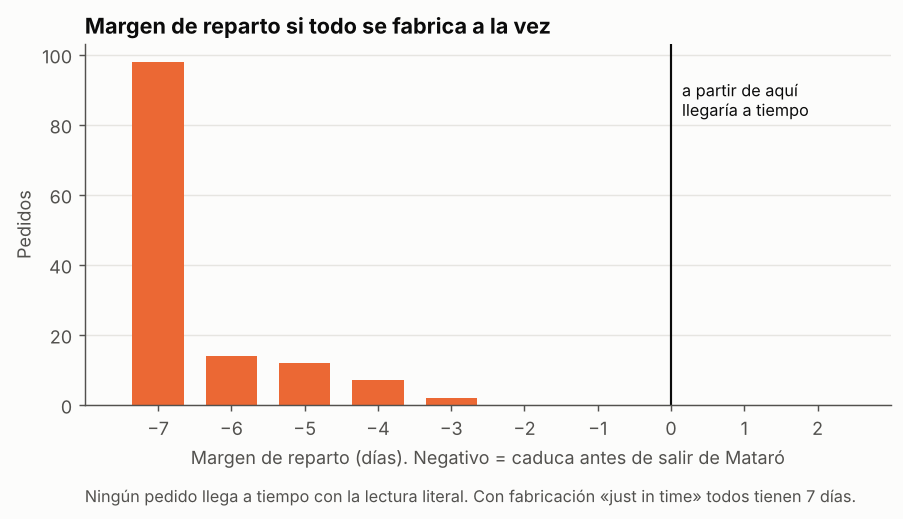

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
m = O["MargenDias"].value_counts().sort_index()
ax.bar(m.index, m.values, color=NARANJA, width=.7)
ax.axvline(0, color=TINTA, lw=1.2)
ax.text(.15, ax.get_ylim()[1] * .9, "a partir de aquí\nllegaría a tiempo", fontsize=9, va="top")
ax.set_xlim(-8, 3); ax.set_xticks(range(-7, 3)); ax.grid(axis="x", visible=False)
ax.set_xlabel("Margen de reparto (días). Negativo = caduca antes de salir de Mataró"); ax.set_ylabel("Pedidos")
ax.set_title("Margen de reparto si todo se fabrica a la vez")
ax.text(0, -0.27, "Ningún pedido llega a tiempo con la lectura literal. Con fabricación «just in time» todos tienen 7 días.",
        transform=ax.transAxes, fontsize=9, color=TINTA2)
guardar(fig, "eda_06_margen_caducidad")

## 6. Destinos

Pintamos los 1.500 destinos sobre la línea de costa (calculada con una máscara de tierra/mar, sin conexión a internet).

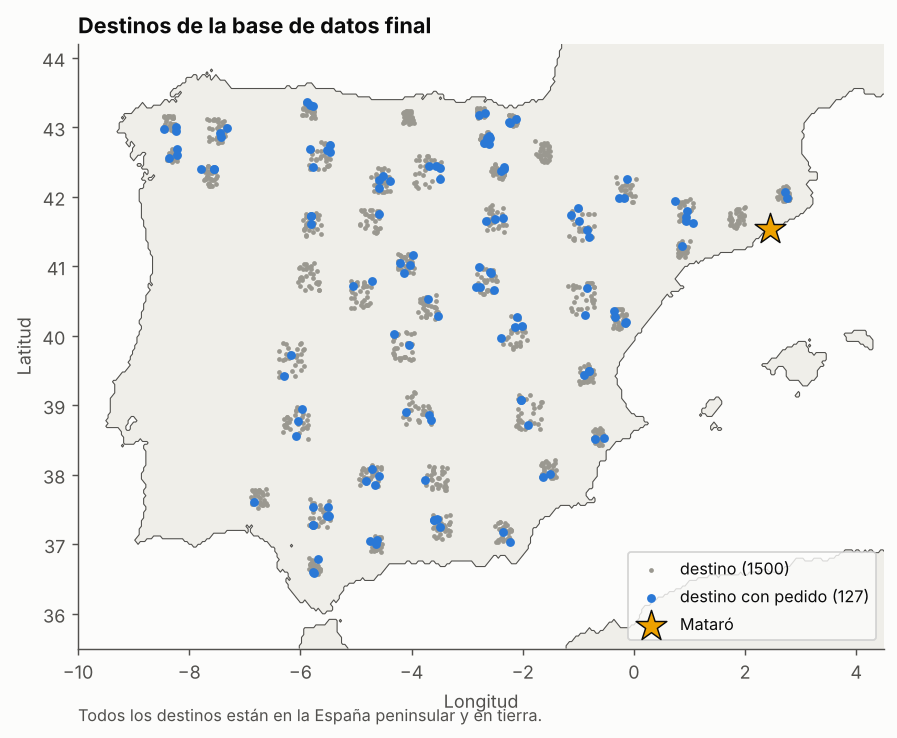

In [9]:
from global_land_mask import globe
lats = np.arange(35.5, 44.3, 0.04); lons = np.arange(-10, 4.6, 0.04)
LON, LAT = np.meshgrid(lons, lats)
tierra = globe.is_land(LAT, LON)

D = t["Destinos"]
fig, ax = plt.subplots(figsize=(8, 6.4))
ax.contourf(LON, LAT, tierra, levels=[0.5, 1.5], colors=["#efeee9"])
ax.contour(LON, LAT, tierra, levels=[0.5], colors=[TINTA2], linewidths=.6)
ax.scatter(D["Longitud"], D["Latitud"], s=7, color="#9a9890", lw=0, label=f"destino ({len(D)})")
ax.scatter(O["Longitud"], O["Latitud"], s=24, color=AZUL, lw=0, label=f"destino con pedido ({O['IdDestino'].nunique()})")
ax.scatter(MATARO_LON, MATARO_LAT, marker="*", s=320, color="#eda100", edgecolors=TINTA, lw=.8, zorder=5, label="Mataró")
ax.set_xlim(-10, 4.5); ax.set_ylim(35.5, 44.2); ax.set_aspect(1.25); ax.grid(False)
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
ax.set_title("Destinos de la base de datos final")
ax.legend(loc="lower right", frameon=True, fontsize=9)
ax.text(0, -0.12, "Todos los destinos están en la España peninsular y en tierra.",
        transform=ax.transAxes, fontsize=9, color=TINTA2)
guardar(fig, "eda_07_mapa_destinos")

## 7. Comparación con la base de datos inicial

Mismas comprobaciones sobre las dos bases de datos (los resultados de la inicial se guardaron antes de quitarla del repositorio). Para el país y la provincia buscamos la población real
más cercana a cada coordenada (base de datos GeoNames, librería `reverse_geocoder`).

In [10]:
import unicodedata
import reverse_geocoder as rg

def _n(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    for x in ["provincia de ", "province of "]:
        s = s.replace(x, "")
    alias = {"araba": "alava", "bizkaia": "vizcaya", "gipuzkoa": "guipuzcoa", "la coruna": "a coruna",
             "lerida": "lleida", "gerona": "girona", "orense": "ourense", "castello": "castellon", "alacant": "alicante"}
    return alias.get(s.strip(), s.strip())

def comprobar(tablas):
    d = tablas["Destinos"]; prov = tablas["Provincias"].set_index("IdProvincia")["Nombre"]
    mar = ~globe.is_land(d["Latitud"].to_numpy(), d["Longitud"].to_numpy())
    r = rg.search(list(zip(d["Latitud"], d["Longitud"])), mode=1, verbose=False)
    cc = np.array([x["cc"] for x in r]); adm = [x["admin2"] or x["admin1"] for x in r]
    pais_ok = (~mar) & (d["Pais"].map({"España": "ES", "Portugal": "PT", "Andorra": "AD"}).to_numpy() == cc)
    prov_ok = np.array([_n(prov[p]) in _n(a) or _n(a) in _n(prov[p]) for p, a in zip(d["IdProvincia"], adm)])
    geo_ok = ((d["Latitud"] - d["GeoLatitud"]).abs() < 1e-4) & ((d["Longitud"] - d["GeoLongitud"]).abs() < 1e-4)
    n = len(d)
    return {"En tierra": 100 * (~mar).mean(), "País correcto": 100 * pais_ok.mean(),
            "Provincia correcta": 100 * (pais_ok & prov_ok).sum() / n, "Coordenadas = Lat/Lon": 100 * geo_ok.mean()}

# La BBDD inicial ya no está en el repo: usamos los resultados que calculamos con ella
# (misma función comprobar), guardados en data/processed/calidad_destinos_bbdd_inicial.csv
ini = pd.read_csv(ROOT / "data" / "processed" / "calidad_destinos_bbdd_inicial.csv", index_col=0)["Porcentaje"].to_dict()
fin = comprobar(t)
comp = pd.DataFrame({"BBDD inicial": ini, "BBDD final": fin}).round(1)
comp

,BBDD inicial,BBDD final
En tierra,76.7,100.0
País correcto,62.7,100.0
Provincia correcta,0.9,99.2
Coordenadas = Lat/Lon,0.0,100.0


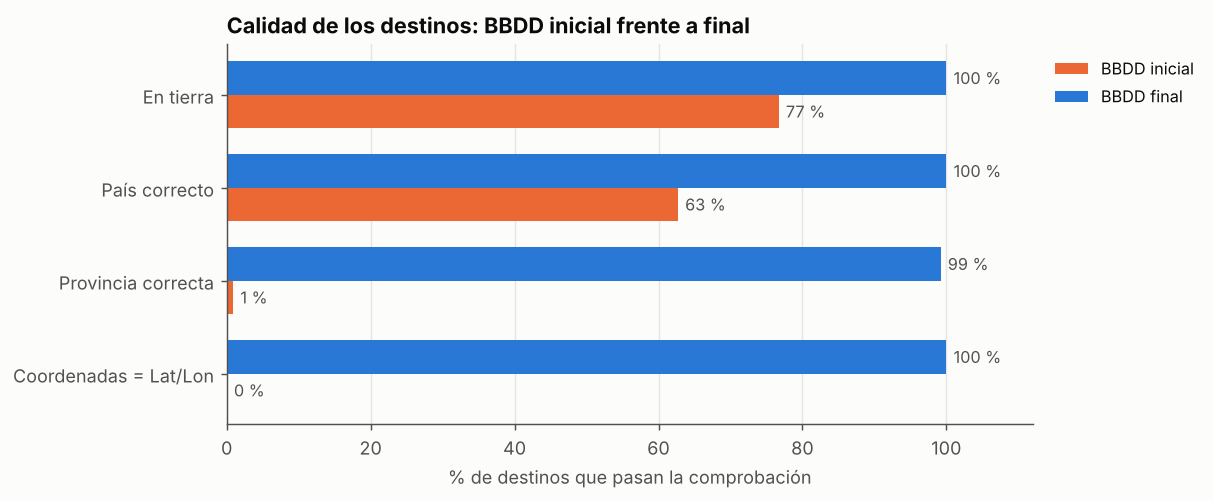

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(comp)); h = .36
ax.barh(y + h / 2, comp["BBDD inicial"], height=h, color=NARANJA, label="BBDD inicial")
ax.barh(y - h / 2, comp["BBDD final"], height=h, color=AZUL, label="BBDD final")
for i, (a, b) in enumerate(zip(comp["BBDD inicial"], comp["BBDD final"])):
    ax.text(a + 1, i + h / 2, f"{a:.0f} %", va="center", fontsize=9, color=TINTA2)
    ax.text(b + 1, i - h / 2, f"{b:.0f} %", va="center", fontsize=9, color=TINTA2)
ax.set_yticks(y, comp.index); ax.invert_yaxis(); ax.set_xlim(0, 112); ax.grid(axis="y", visible=False)
ax.set_xlabel("% de destinos que pasan la comprobación")
ax.set_title("Calidad de los destinos: BBDD inicial frente a final")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
guardar(fig, "eda_08_comparacion_bbdd")

## 8. Conclusiones para el diseño del optimizador

| Lo que hemos visto | Qué implica |
|---|---|
| 133 pedidos, misma fecha, 133 líneas cada uno, los 10 tipos en todos | Un solo escenario real y muy homogéneo: hay que generar escenarios extra para probar |
| 4.400–9.000 unidades por pedido | La capacidad del camión (parámetro) decide cuántos pedidos caben por ruta |
| 56–910 km desde Mataró | Viajes de hasta ~11 h de ida a 80 km/h |
| Ensalada Preparada (7 días) en todos los pedidos | Lectura literal imposible → fabricación «just in time», 7 días de margen |
| Coordenadas reales, todas en España | Ya se pueden usar para rutas y mapas; no hay destinos en Portugal ni Andorra |